# Run types: automatically labelling workouts, and runners as a mix

Notebook 1 (`analysis/athlete_profiles`) clustered **athletes** directly. Here we take the alternative route:

1. Cluster **individual runs** into *run types* (easy, long, tempo, fartlek, …), based on the shape of the speed/HR time series.
2. Describe each **athlete as a mix** of those run types.
3. Cluster athletes on that mix, and compare with notebook 1, including the same stability test over time.

| Step | What happens |
|---|---|
| 1 | Load the workouts |
| 2 | Features per run: shape of the run + relative to the athlete's own baseline |
| 3 | Choose features |
| 4 | Choose the number of run types *k* |
| 5 | The run types: centres and "typical runs" |
| 6 | Sanity check against the dataset's workout type |
| 7 | Does the model generalise to new athletes? |
| 8 | Auto-label a new run |
| 9 | Athletes as a mix of run types → profiles |
| 10 | Stability over time: mix profiles vs notebook 1 |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())
SRC = ROOT / "data" / "endomondo-hr-prediction-v2" / "dataset.parquet"
OUT = ROOT / "analysis" / "run_types" / "output"
NB1_LABELS = ROOT / "analysis" / "athlete_profiles" / "output" / "final_labels.csv"
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
MIN_WORKOUTS = 10

# --- chart style (same as notebook 1) -------------------------------------
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e0"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, RED, NEUTRAL = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                                     "#e87ba4", "#e34948", "#f0efec")
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, NEUTRAL, RED])
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#2a78d6", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "legend.frameon": False, "lines.linewidth": 2,
})

# Run types get the first five categorical slots, in fixed order.
RUN_ORDER = ["Easy / short", "Long & steady", "Tempo / hard", "Fartlek / variable", "Stop-and-go"]
RUN_COLOR = dict(zip(RUN_ORDER, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))

## Step 1 · Load the workouts

We use athletes with **≥ 10 workouts**: several features are *relative to the athlete's own baseline* (step 2), and that requires enough runs to know what is "normal" for them.

In [2]:
cols = ["workout_id", "user_id", "workout_type", "duration_min", "timestamp", "heart_rate", "speed",
        "hr_mean", "speed_mean", "altitude_gain"]
df = pd.read_parquet(SRC, columns=cols)
df = df[df.user_id.map(df.groupby("user_id").size()) >= MIN_WORKOUTS].reset_index(drop=True)

hr = np.stack(df["heart_rate"].to_numpy()).astype("float32")      # (runs, 500)
sp = np.stack(df["speed"].to_numpy()).astype("float32")
df["date"] = pd.to_datetime(df["timestamp"].map(lambda t: t[0]), unit="s")
df["distance_km"] = df.speed_mean * df.duration_min / 60
df = df.drop(columns=["heart_rate", "speed", "timestamp"])
print(f"{len(df):,} runs from {df.user_id.nunique()} athletes")

39,459 runs from 569 athletes


## Step 2 · Features per run

Two kinds of features:

**Shape of the run** (from the time series, compared with the run's own median speed):

| Feature | Meaning |
|---|---|
| `n_surges` | how often speed rises above 115% of the run's median: intervals / fartlek |
| `frac_fast` | share of the run above 115% |
| `frac_slow` | share of the run below 75%: walking, stops, traffic lights |
| `speed_cv` | overall speed variation |
| `hr_range_rel` | heart-rate range (p95 − p5) relative to mean HR |
| `split_ratio` | speed 2nd half / 1st half (> 1 = negative split) |
| `climb_m_per_km` | elevation gain per km |

**Relative to the athlete** (compared with *their own* median, so a 12 km/h run is "fast" for one runner and "easy" for another):

| Feature | Meaning |
|---|---|
| `rel_hr` | mean HR / athlete's median HR |
| `rel_speed` | mean speed / athlete's median speed |
| `rel_dist` | log(distance / athlete's median distance): long run > 0 |

In [3]:
def shape_features(sp_, hr_, meta):
    med = np.median(sp_, axis=1)
    fast = sp_ > 1.15 * med[:, None]
    slow = sp_ < 0.75 * med[:, None]
    half = sp_.shape[1] // 2
    return pd.DataFrame({
        "n_surges": (np.diff(fast.astype(np.int8), axis=1) == 1).sum(1),
        "frac_fast": fast.mean(1),
        "frac_slow": slow.mean(1),
        "speed_cv": sp_.std(1) / np.clip(sp_.mean(1), 0.1, None),
        "hr_range_rel": (np.percentile(hr_, 95, axis=1) - np.percentile(hr_, 5, axis=1)) / hr_.mean(1),
        "split_ratio": sp_[:, half:].mean(1) / np.clip(sp_[:, :half].mean(1), 0.1, None),
        "climb_m_per_km": (meta.altitude_gain / meta.distance_km.clip(lower=0.5)).to_numpy(),
    }, index=meta.index)

def relative_features(meta, baseline):
    b = baseline.reindex(meta.user_id)
    return pd.DataFrame({
        "rel_hr": meta.hr_mean.to_numpy() / b.hr_mean.to_numpy(),
        "rel_speed": meta.speed_mean.to_numpy() / b.speed_mean.to_numpy(),
        "rel_dist": np.log(meta.distance_km.to_numpy() / b.distance_km.to_numpy()),
    }, index=meta.index)

def make_baseline(meta):
    return meta.groupby("user_id")[["hr_mean", "speed_mean", "distance_km"]].median()

runs = pd.concat([df, shape_features(sp, hr, df), relative_features(df, make_baseline(df))], axis=1)
runs.iloc[:, 9:].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
n_surges,39459.0,3.203,3.748,0.000,0.000,2.000,5.000,30.000
frac_fast,39459.0,0.063,0.095,0.000,0.000,0.020,0.080,0.498
frac_slow,39459.0,0.043,0.070,0.000,0.002,0.012,0.048,0.494
speed_cv,39459.0,0.119,0.086,0.014,0.065,0.093,0.142,2.213
hr_range_rel,39459.0,0.199,0.091,0.026,0.134,0.181,0.244,0.829
split_ratio,39459.0,1.021,0.902,0.300,0.971,1.006,1.044,115.688
climb_m_per_km,39459.0,9.389,8.918,0.000,4.370,7.287,11.743,362.747
rel_hr,39459.0,1.002,0.061,0.746,0.966,1.000,1.034,1.389
rel_speed,39459.0,0.999,0.106,0.214,0.950,1.000,1.051,2.349
rel_dist,39459.0,0.011,0.421,-2.531,-0.209,0.000,0.243,1.778


### What do the shape features look like?

Three real runs: a steady run, a run with many surges, and a stop-and-go run. Orange = above 115% of the median speed (a *surge* starts every time the line goes into orange), grey = below 75% (slow / stopped).

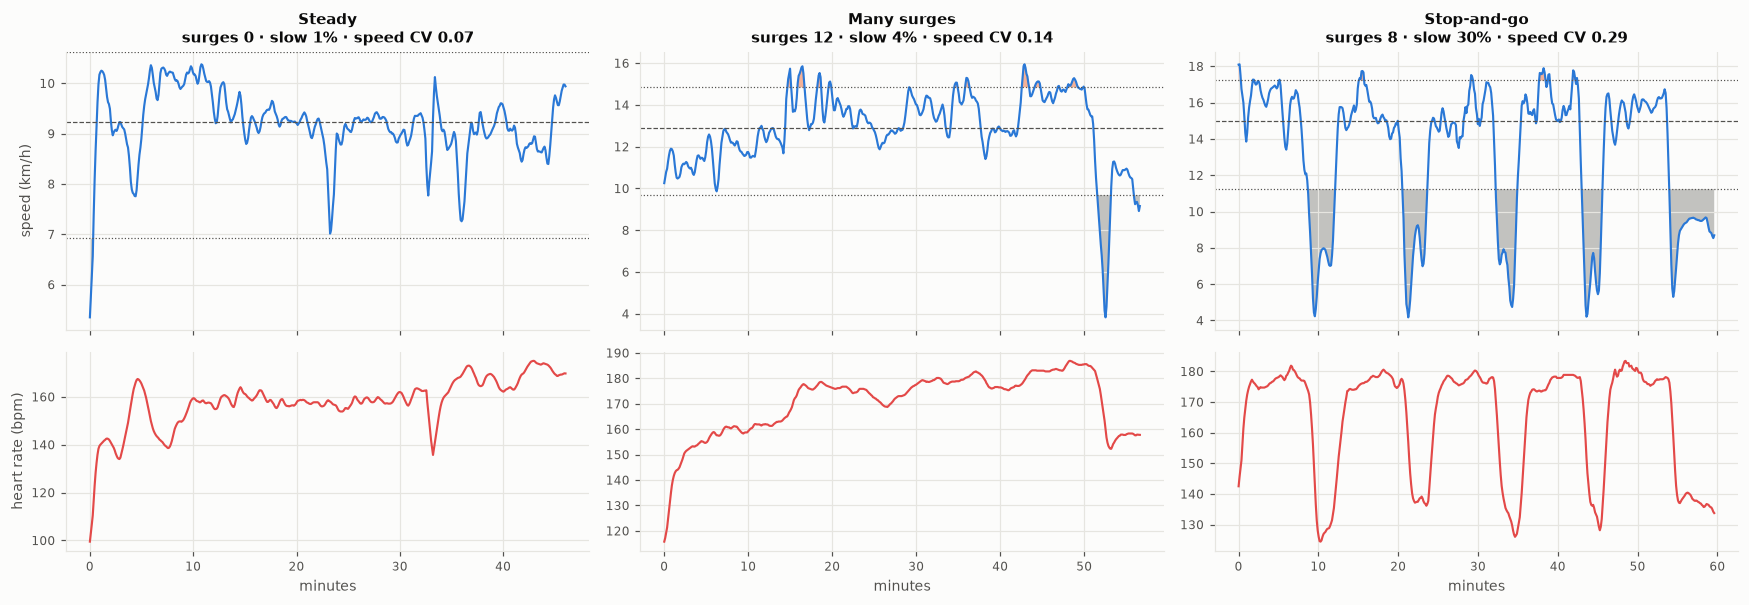

In [4]:
def pick(q):
    return runs.query(q).sample(1, random_state=3).index[0]

examples = {
    "Steady": pick("n_surges == 0 and frac_slow < 0.01 and 40 < duration_min < 70"),
    "Many surges": pick("n_surges >= 9 and frac_slow < 0.05 and 40 < duration_min < 70"),
    "Stop-and-go": pick("frac_slow > 0.25 and 40 < duration_min < 70"),
}
fig, axes = plt.subplots(2, 3, figsize=(16, 5.6), sharex="col", gridspec_kw={"height_ratios": [1.4, 1]})
for c, (title, i) in enumerate(examples.items()):
    t = np.linspace(0, runs.loc[i, "duration_min"], sp.shape[1])
    s, h = sp[i], hr[i]
    med = np.median(s)
    ax = axes[0, c]
    ax.fill_between(t, med * 1.15, s, where=s > med * 1.15, color=ORANGE, alpha=0.5, lw=0, interpolate=True)
    ax.fill_between(t, s, med * 0.75, where=s < med * 0.75, color=MUTED, alpha=0.5, lw=0, interpolate=True)
    ax.plot(t, s, color=BLUE, lw=1.4)
    for m_, ls in [(1.15, ":"), (1, "--"), (0.75, ":")]:
        ax.axhline(med * m_, color=INK2, ls=ls, lw=0.8)
    r = runs.loc[i]
    ax.set_title(f"{title}\nsurges {r.n_surges:.0f} · slow {r.frac_slow:.0%} · speed CV {r.speed_cv:.2f}", fontsize=10)
    ax.set_ylabel("speed (km/h)" if c == 0 else None)
    axes[1, c].plot(t, h, color=RED, lw=1.4)
    axes[1, c].set(xlabel="minutes", ylabel="heart rate (bpm)" if c == 0 else None)
fig.tight_layout()

## Step 3 · Choose features

As in notebook 1: features that measure the same thing count double. The speed-variation features overlap strongly.

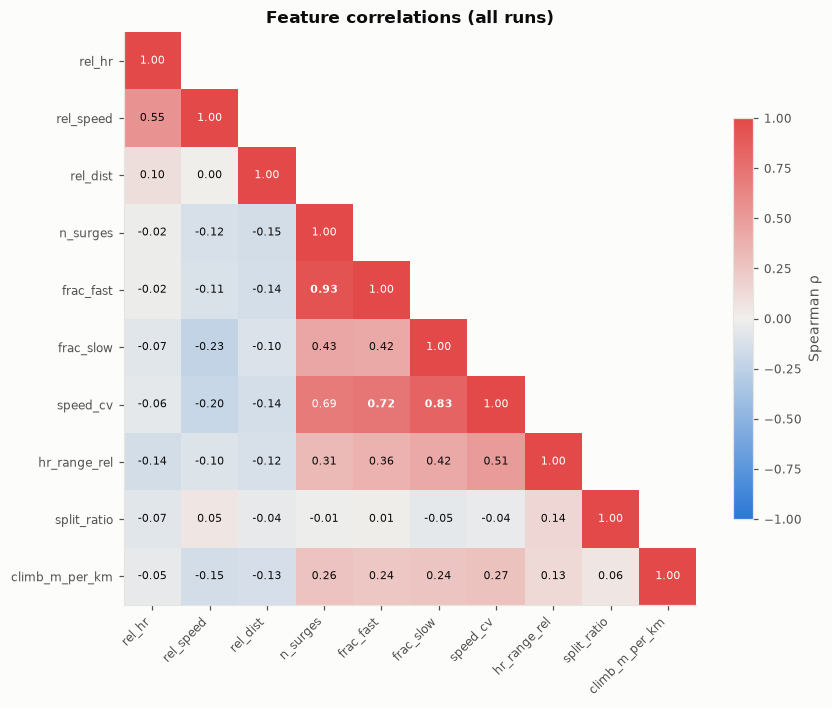

In [5]:
CANDIDATES = ["rel_hr", "rel_speed", "rel_dist", "n_surges", "frac_fast", "frac_slow", "speed_cv",
              "hr_range_rel", "split_ratio", "climb_m_per_km"]
corr = runs[CANDIDATES].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(np.where(mask, np.nan, corr), cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for r in range(len(corr)):
    for c in range(r + 1):
        v = corr.iat[r, c]
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else INK,
                fontweight="bold" if abs(v) > 0.7 and r != c else None)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman ρ")
ax.set_title("Feature correlations (all runs)")
fig.tight_layout()

* `n_surges` ↔ `frac_fast` (ρ ≈ 0.93): keep **n_surges** (counting surges says more about intervals than the share).
* `speed_cv` ↔ `frac_slow` / `n_surges` (ρ ≈ 0.7–0.8): `speed_cv` is the sum of both, so we drop it and keep the two separate signals (*surges* vs *stops*).
* `split_ratio` is **dropped too**, after a first attempt. With it, k-means split the irregular runs into "slow at the start" and "slow at the end". That's not a meaningful run type, and the split was unstable: models fit on different athletes swapped those two groups (~70% agreement in step 7). Without `split_ratio` that agreement is ~90%.

That leaves 7 features. Transformations: log for `n_surges` and `climb`, clip at 0.5–99.5%, then z-scores.

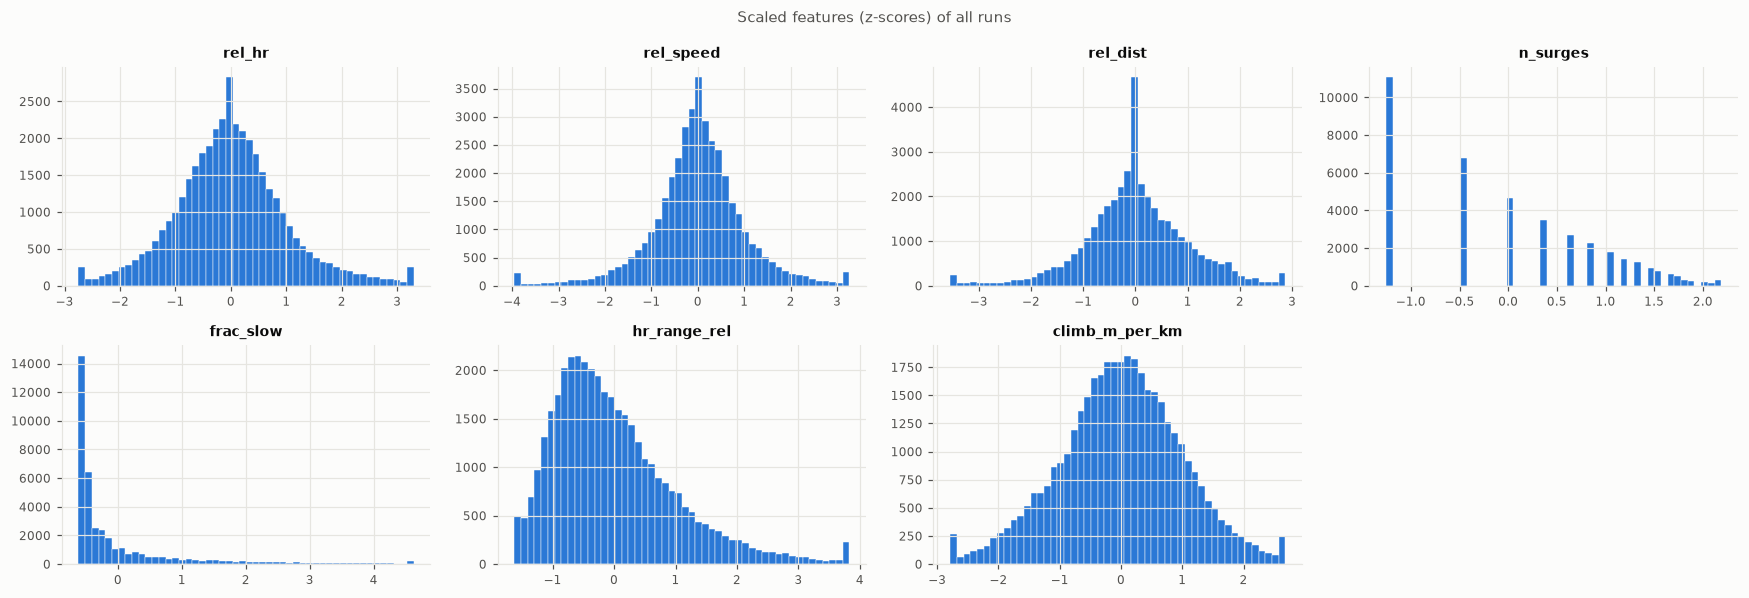

In [6]:
FEATURES = ["rel_hr", "rel_speed", "rel_dist", "n_surges", "frac_slow", "hr_range_rel", "climb_m_per_km"]

def prepare(r):
    X = r[FEATURES].copy()
    X["n_surges"] = np.log1p(X["n_surges"])
    X["climb_m_per_km"] = np.log1p(X["climb_m_per_km"].clip(lower=0))
    return X

def name_run_types(z):
    # Name clusters from their centres; order matters (stop-and-go also has many 'surges').
    left, names = set(z.index), {}
    for col, name in [("frac_slow", "Stop-and-go"), ("rel_hr", "Tempo / hard"),
                      ("n_surges", "Fartlek / variable"), ("rel_dist", "Long & steady")]:
        c = z.loc[sorted(left), col].idxmax()
        names[c] = name
        left.remove(c)
    names[left.pop()] = "Easy / short"
    return names

def fit_run_model(r, k=5, seed=SEED):
    # Full pipeline (transform, clip, scale, k-means, names), fit on runs r.
    Xr = prepare(r)
    lo, hi = Xr.quantile(0.005), Xr.quantile(0.995)
    sc = StandardScaler().fit(Xr.clip(lo, hi, axis=1))
    tf = lambda b: sc.transform(prepare(b).clip(lo, hi, axis=1))
    Xs = tf(r)
    km = KMeans(k, n_init=10, random_state=seed).fit(Xs)
    names = name_run_types(pd.DataFrame(Xs, columns=FEATURES).groupby(km.labels_).mean()) if k == 5 else None
    predict = lambda b: pd.Categorical([names[l] for l in km.predict(tf(b))], categories=RUN_ORDER)
    return dict(tf=tf, km=km, names=names, predict=predict, X=Xs)

base = fit_run_model(runs, k=5)
X = base["X"]
fig, axes = plt.subplots(2, 4, figsize=(16, 5.5))
axes.flat[-1].axis("off")
for ax, f in zip(axes.flat, FEATURES):
    ax.hist(X[:, FEATURES.index(f)], bins=50, color=BLUE, edgecolor="#fcfcfb", lw=0.3)
    ax.set_title(f, fontsize=9)
fig.suptitle("Scaled features (z-scores) of all runs", fontsize=10, color=INK2)
fig.tight_layout()

## Step 4 · How many run types?

Same measures as notebook 1. Silhouette is computed on a sample of 8,000 runs (it's slow on 39k). Stability: refit on 8 random halves of the runs and check whether the same split comes back.

,inertia,silhouette,stability,smallest
k,,,,
3,194735.989,0.155,0.945,7133
4,175101.737,0.153,0.946,4158
5,163317.866,0.146,0.924,3913
6,154099.682,0.144,0.861,3181
7,146756.481,0.120,0.579,2932
8,139851.178,0.130,0.843,2728


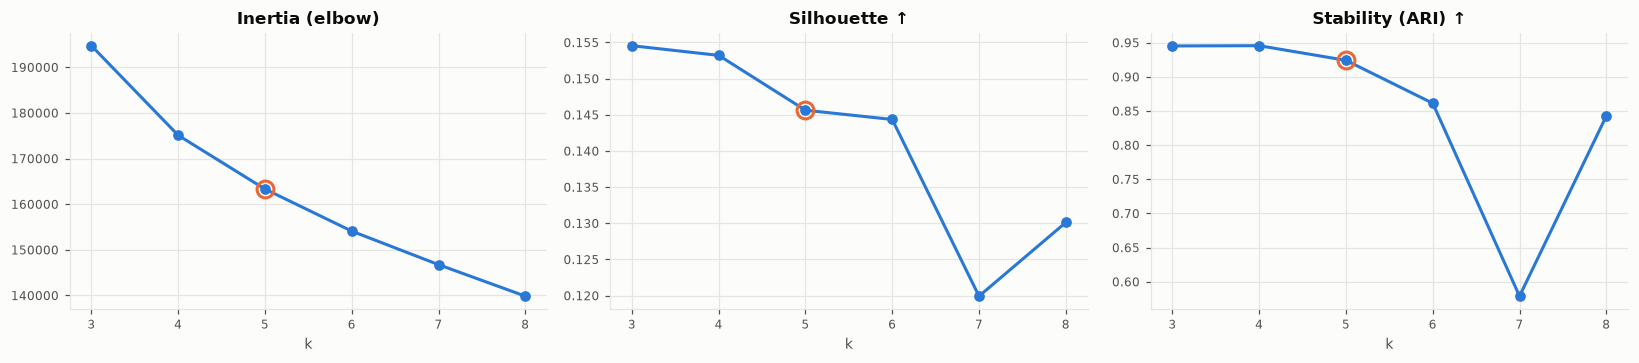

In [7]:
rng = np.random.default_rng(SEED)
sub = rng.choice(len(X), 8000, replace=False)
rows = []
for k in range(3, 9):
    km_k = KMeans(k, n_init=5, random_state=SEED).fit(X)
    aris = []
    for _ in range(8):
        idx = rng.choice(len(X), len(X) // 2, replace=False)
        kb = KMeans(k, n_init=3, random_state=int(rng.integers(1e9))).fit(X[idx])
        aris.append(adjusted_rand_score(km_k.labels_, kb.predict(X)))
    rows.append(dict(k=k, inertia=km_k.inertia_, silhouette=silhouette_score(X[sub], km_k.labels_[sub]),
                     stability=np.mean(aris), smallest=np.bincount(km_k.labels_).min()))
scores = pd.DataFrame(rows).set_index("k")

K = 5
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
for ax, (col, title) in zip(axes, {"inertia": "Inertia (elbow)", "silhouette": "Silhouette ↑",
                                   "stability": "Stability (ARI) ↑"}.items()):
    ax.plot(scores.index, scores[col], color=BLUE, marker="o", ms=6)
    ax.plot(K, scores.loc[K, col], "o", ms=11, mfc="none", mec=ORANGE, mew=2)
    ax.set(title=title, xlabel="k", xticks=scores.index)
fig.tight_layout()
scores.round(3)

We choose **k = 5**. The silhouette barely differs between k = 3 and 6 (≈ 0.15, low: runs flow into each other too), and stability stays high up to k = 5 (≈ 0.92) before dropping at k = 6–7. So k = 5 is the largest number of types that still comes back reliably, and 3 types would be too coarse to be useful as *run labels*. Step 5 shows that the five groups are each recognisable.

## Step 5 · The run types

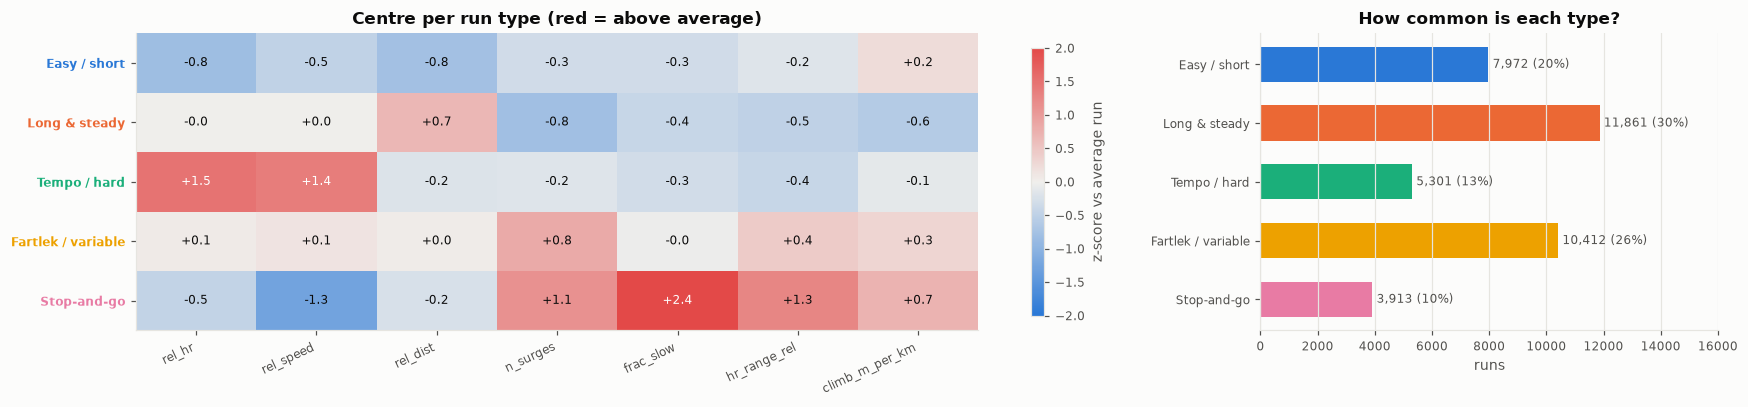

In [8]:
runs["run_type"] = base["predict"](runs)
z_run = pd.DataFrame(X, columns=FEATURES).groupby(runs.run_type.to_numpy(), observed=False).mean().loc[RUN_ORDER]
counts = runs.run_type.value_counts().reindex(RUN_ORDER)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={"width_ratios": [2.3, 1]})
im = a1.imshow(z_run.values, cmap=DIVERGING, vmin=-2, vmax=2, aspect="auto")
a1.set_xticks(range(len(FEATURES)), FEATURES, rotation=25, ha="right")
a1.set_yticks(range(K), RUN_ORDER)
for tick, n in zip(a1.get_yticklabels(), RUN_ORDER):
    tick.set_color(RUN_COLOR[n]); tick.set_fontweight("bold")
for r in range(K):
    for c in range(len(FEATURES)):
        v = z_run.iat[r, c]
        a1.text(c, r, f"{v:+.1f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 1.3 else INK)
a1.grid(False)
fig.colorbar(im, ax=a1, label="z-score vs average run", shrink=0.9)
a1.set_title("Centre per run type (red = above average)")

a2.barh(RUN_ORDER, counts, color=[RUN_COLOR[n] for n in RUN_ORDER], height=0.6)
for yi, v in enumerate(counts):
    a2.text(v + 150, yi, f"{v:,} ({v / counts.sum():.0%})", va="center", fontsize=8, color=INK2)
a2.invert_yaxis()
a2.set(xlim=(0, counts.max() * 1.35), xlabel="runs", title="How common is each type?")
a2.grid(axis="y", visible=False)
fig.tight_layout()

In real units: each box is the middle 50% of the runs of that type.

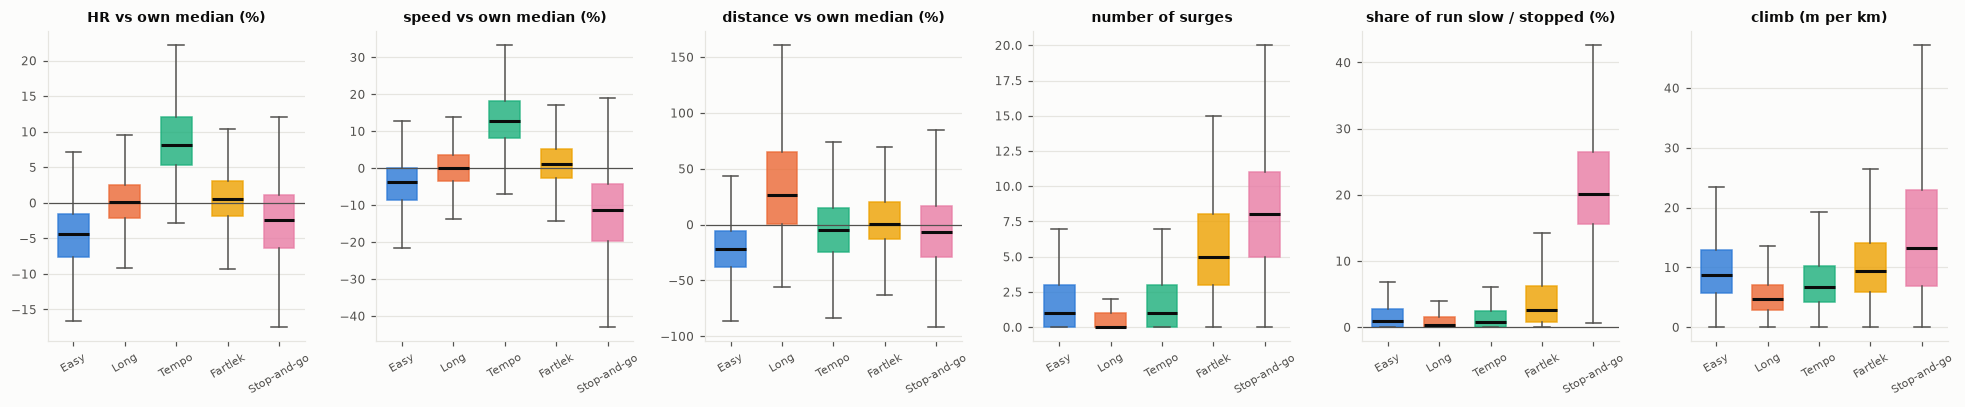

In [9]:
real = {"rel_hr": ("HR vs own median", lambda s: (s - 1) * 100, "%"),
        "rel_speed": ("speed vs own median", lambda s: (s - 1) * 100, "%"),
        "rel_dist": ("distance vs own median", lambda s: (np.exp(s) - 1) * 100, "%"),
        "n_surges": ("number of surges", lambda s: s, ""),
        "frac_slow": ("share of run slow / stopped", lambda s: s * 100, "%"),
        "climb_m_per_km": ("climb (m per km)", lambda s: s, "")}
fig, axes = plt.subplots(1, len(real), figsize=(18, 3.8))
for ax, (f, (label, conv, unit)) in zip(axes, real.items()):
    data = [conv(runs.loc[runs.run_type == n, f]) for n in RUN_ORDER]
    bp = ax.boxplot(data, positions=range(K), widths=0.6, showfliers=False, patch_artist=True,
                    medianprops=dict(color=INK, lw=2), whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
    for patch, n in zip(bp["boxes"], RUN_ORDER):
        patch.set(facecolor=RUN_COLOR[n], edgecolor=RUN_COLOR[n], alpha=0.8)
    if unit == "%":
        ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(range(K), [n.split(" ")[0] for n in RUN_ORDER], rotation=30, fontsize=7)
    ax.set_title(label + (f" ({unit})" if unit else ""), fontsize=9)
    ax.grid(axis="x", visible=False)
fig.tight_layout()

### Typical runs per type

The strongest evidence that the labels mean something: the **4 runs closest to the centre** of each type, as a speed profile. Dashed = the run's median speed.

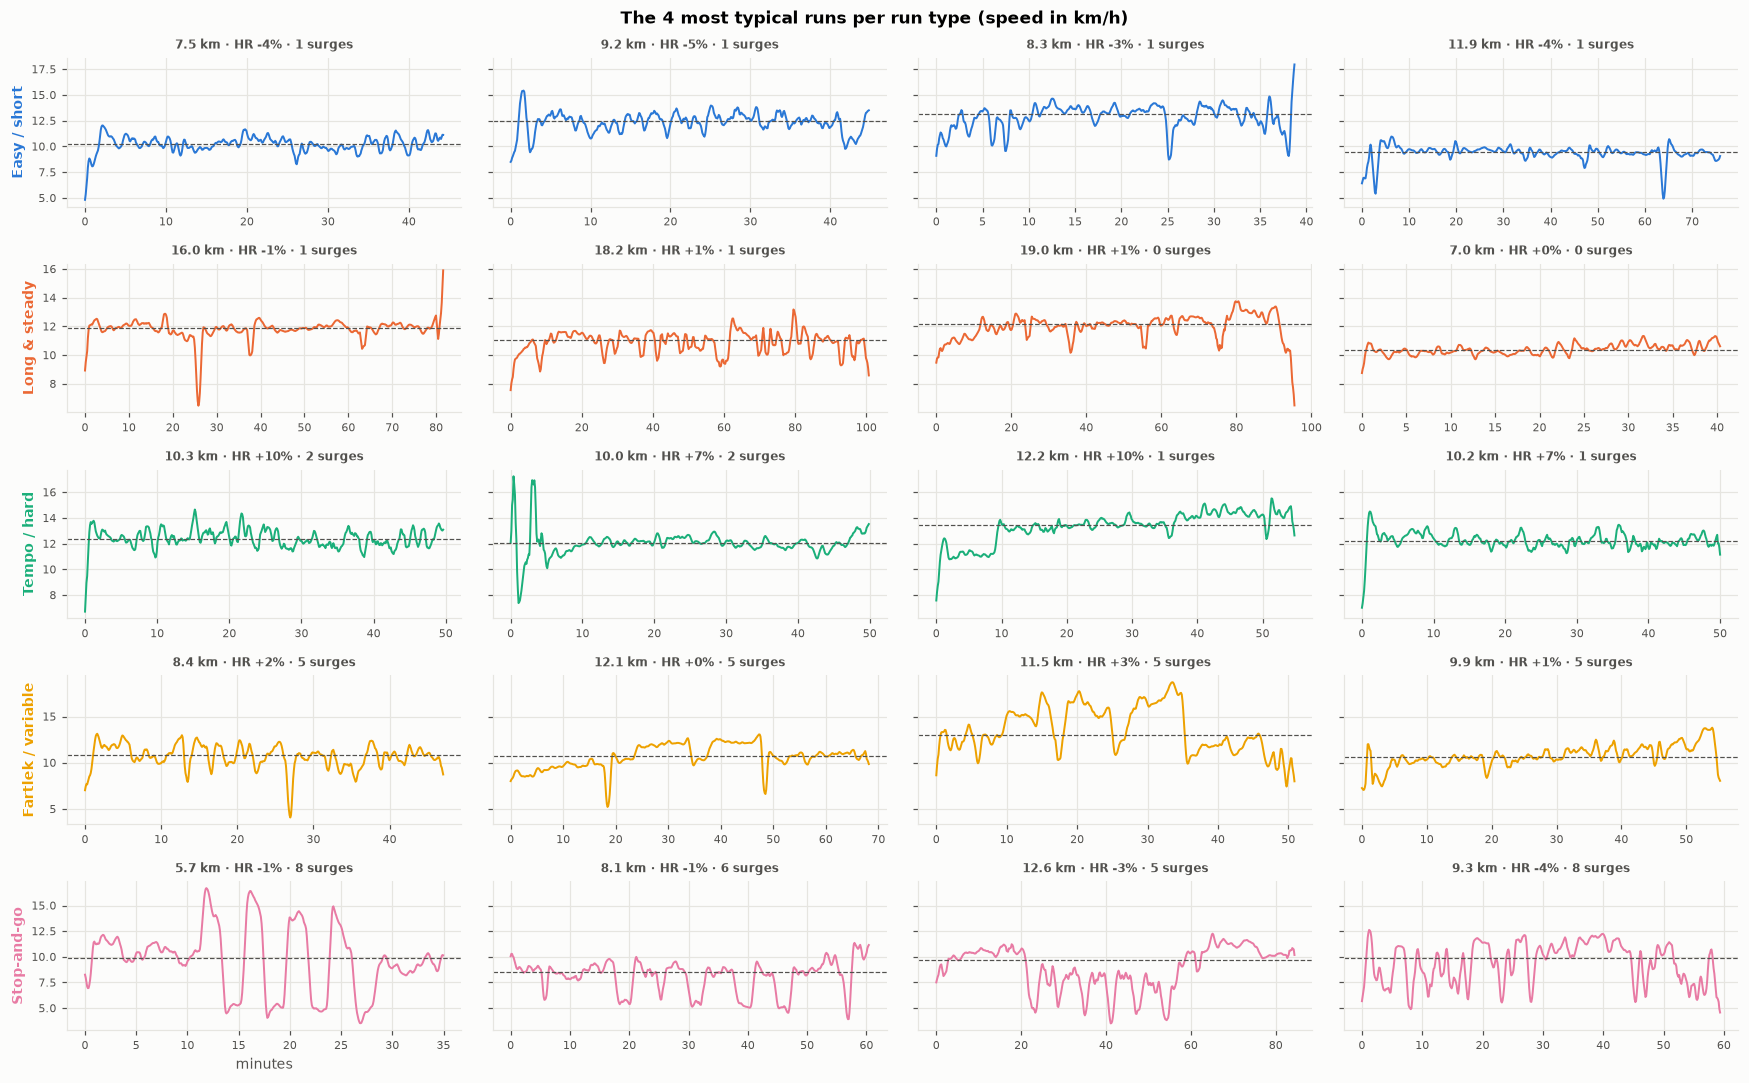

In [10]:
d_centre = base["km"].transform(X)
lab_idx = base["km"].labels_
inv = {v: k for k, v in base["names"].items()}
fig, axes = plt.subplots(K, 4, figsize=(16, 2.0 * K), sharey="row")
for r, n in enumerate(RUN_ORDER):
    c_id = inv[n]
    members = np.where(lab_idx == c_id)[0]
    typical = members[np.argsort(d_centre[members, c_id])[:4]]
    for c, i in enumerate(typical):
        ax = axes[r, c]
        t = np.linspace(0, runs.loc[i, "duration_min"], sp.shape[1])
        ax.plot(t, sp[i], color=RUN_COLOR[n], lw=1.3)
        ax.axhline(np.median(sp[i]), color=INK2, ls="--", lw=0.8)
        ax.set_title(f"{runs.loc[i, 'distance_km']:.1f} km · HR {100 * (runs.loc[i, 'rel_hr'] - 1):+.0f}% · "
                     f"{runs.loc[i, 'n_surges']:.0f} surges", fontsize=8, color=INK2)
        ax.tick_params(labelsize=7)
        if c == 0:
            ax.set_ylabel(n, fontsize=9, color=RUN_COLOR[n], fontweight="bold")
axes[-1, 0].set_xlabel("minutes")
fig.suptitle("The 4 most typical runs per run type (speed in km/h)", fontsize=11, fontweight="bold")
fig.tight_layout()

## Step 6 · Sanity check: the dataset's workout type

The dataset has its own label (RECOVERY / STEADY / INTENSIVE), but that's purely an absolute heart-rate threshold (see notebook 1). Our run types should line up with it where it makes sense: *Tempo / hard* more often INTENSIVE, *Easy* more often RECOVERY. On the other run types, the shape of the run says something the HR label can't.

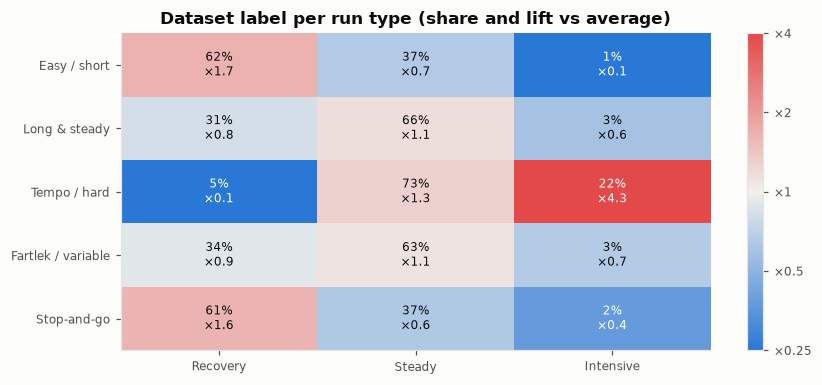

In [11]:
TYPES = ["RECOVERY", "STEADY", "INTENSIVE"]
mix = pd.crosstab(runs.run_type, runs.workout_type, normalize="index").reindex(index=RUN_ORDER, columns=TYPES)
lift = mix / runs.workout_type.value_counts(normalize=True).reindex(TYPES)

fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(np.log2(lift.values), cmap=DIVERGING, vmin=-2, vmax=2, aspect="auto")
for r in range(K):
    for c in range(3):
        ax.text(c, r, f"{mix.iat[r, c]:.0%}\n×{lift.iat[r, c]:.1f}", ha="center", va="center", fontsize=8,
                color="white" if abs(np.log2(lift.iat[r, c])) > 1.2 else INK)
ax.set_xticks(range(3), [t.title() for t in TYPES])
ax.set_yticks(range(K), RUN_ORDER)
ax.grid(False)
ax.set_title("Dataset label per run type (share and lift vs average)")
fig.colorbar(im, ax=ax, ticks=[-2, -1, 0, 1, 2], format=lambda x, _: f"×{2.0 ** x:g}")
fig.tight_layout()

## Step 7 · Does the model work for new athletes?

For auto-labelling, the model must work for runners it has never seen. Test: split the **athletes** randomly into two groups A and B. Fit one model on A and one on B, and label B's runs with both. If the run types are general, both models give the same labels. We repeat this 5 times.

,agree,ari
rep,,
0,0.914,0.789
1,0.958,0.890
2,0.905,0.775
3,0.895,0.748
4,0.934,0.842


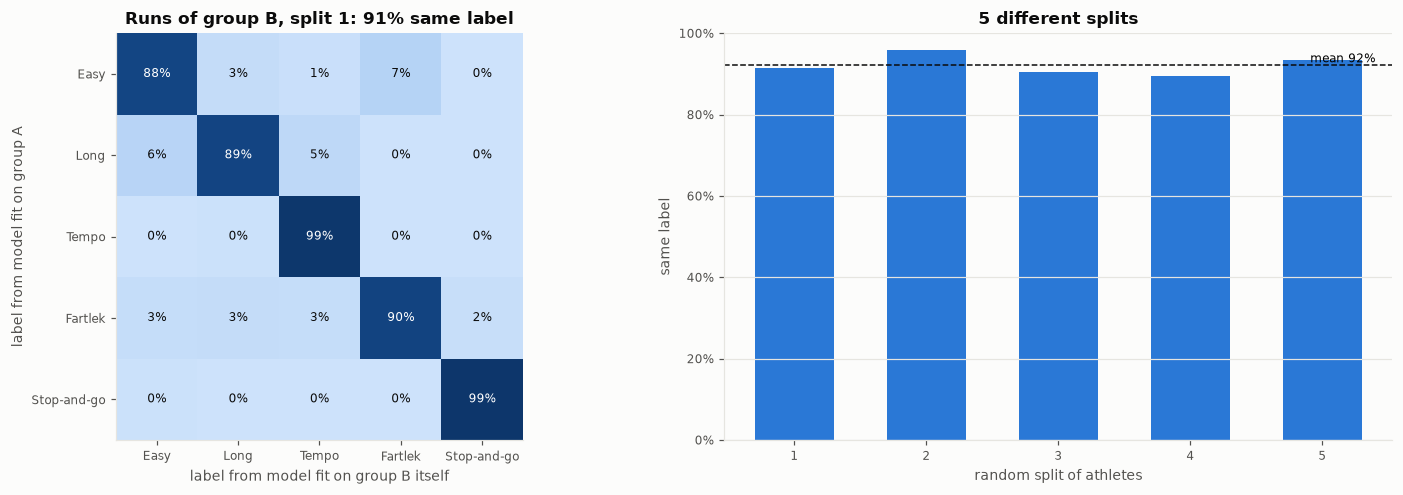

In [12]:
users = runs.user_id.unique()
reps = []
for rep in range(5):
    rng_ = np.random.default_rng(rep)
    a_users = set(rng_.choice(users, len(users) // 2, replace=False))
    in_a = runs.user_id.isin(a_users).to_numpy()
    m_a = fit_run_model(runs[in_a], seed=rep)
    m_b = fit_run_model(runs[~in_a], seed=rep)
    la, lb = m_a["predict"](runs[~in_a]), m_b["predict"](runs[~in_a])
    reps.append(dict(rep=rep, agree=np.mean(np.asarray(la) == np.asarray(lb)), ari=adjusted_rand_score(la, lb),
                     la=la, lb=lb))
gen = pd.DataFrame(reps).set_index("rep")[["agree", "ari"]]

last = reps[0]
ct = pd.crosstab(pd.Series(last["la"], name="model A (other athletes)"), pd.Series(last["lb"], name="model B (own)"),
                 normalize="index", dropna=False).reindex(index=RUN_ORDER, columns=RUN_ORDER, fill_value=0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
a1.imshow(ct.values, cmap=SEQUENTIAL, vmin=0, vmax=1)
for r in range(K):
    for c in range(K):
        v = ct.iat[r, c]
        a1.text(c, r, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > 0.5 else INK)
short = [n.split(" ")[0] for n in RUN_ORDER]
a1.set_xticks(range(K), short, fontsize=8)
a1.set_yticks(range(K), short, fontsize=8)
a1.set(xlabel="label from model fit on group B itself", ylabel="label from model fit on group A")
a1.grid(False)
a1.set_title(f"Runs of group B, split 1: {last['agree']:.0%} same label")
a2.bar(gen.index + 1, gen.agree, color=BLUE, width=0.6)
a2.axhline(gen.agree.mean(), color=INK, ls="--", lw=1)
a2.text(5.4, gen.agree.mean(), f"mean {gen.agree.mean():.0%}", va="bottom", ha="right", fontsize=8)
a2.set(ylim=(0, 1), xlabel="random split of athletes", ylabel="same label", title="5 different splits")
a2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
a2.grid(axis="x", visible=False)
fig.tight_layout()
gen.round(3)

**Result:** models fit on completely different athletes give **~92% the same label** (ARI ≈ 0.8). The run types are therefore not tied to specific runners and work for new users. The remaining differences are mostly *easy* ↔ *fartlek* and *long* ↔ *easy*, runs that sit on the boundary.

## Step 8 · Auto-label a new run

This is what it looks like in practice: a function that takes a single run (time series + the athlete's baseline) and returns a run type. Besides the label we give a **margin** (how clearly the run sits closest to one type, same as notebook 1: `1 − d_nearest / d_second`).

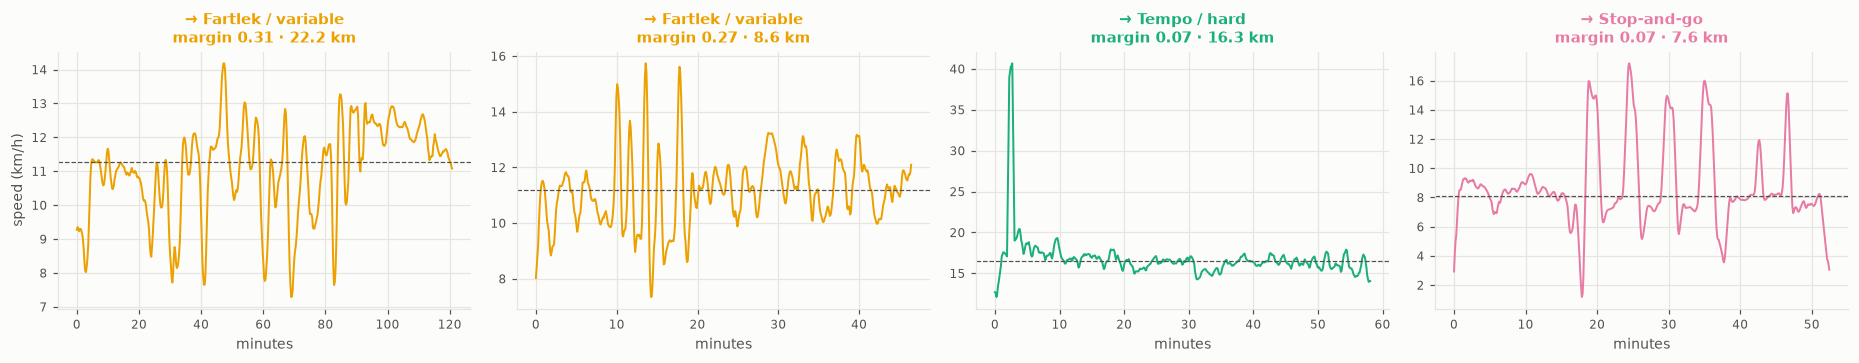

In [13]:
def label_run(speed, heart_rate, duration_min, altitude_gain, athlete_baseline, model=base):
    speed, heart_rate = np.asarray(speed, "float32")[None, :], np.asarray(heart_rate, "float32")[None, :]
    meta = pd.DataFrame({"user_id": [0], "duration_min": [duration_min], "altitude_gain": [altitude_gain],
                         "hr_mean": [heart_rate.mean()], "speed_mean": [speed.mean()]})
    meta["distance_km"] = meta.speed_mean * meta.duration_min / 60
    feats = pd.concat([meta, shape_features(speed, heart_rate, meta),
                       relative_features(meta, athlete_baseline.to_frame().T.set_axis([0]))], axis=1)
    d = model["km"].transform(model["tf"](feats))[0]
    order = np.argsort(d)
    return model["names"][order[0]], 1 - d[order[0]] / d[order[1]], dict(zip(
        [model["names"][i] for i in range(len(d))], d))

# Demo: 4 random runs; the athlete's baseline is their own median.
baseline = make_baseline(runs)
demo = runs.sample(4, random_state=11).index
fig, axes = plt.subplots(1, 4, figsize=(17, 3.4), sharey=False)
for ax, i in zip(axes, demo):
    lab, marg, _ = label_run(sp[i], hr[i], runs.loc[i, "duration_min"], runs.loc[i, "altitude_gain"],
                             baseline.loc[runs.loc[i, "user_id"]])
    t = np.linspace(0, runs.loc[i, "duration_min"], sp.shape[1])
    ax.plot(t, sp[i], color=RUN_COLOR[lab], lw=1.3)
    ax.axhline(np.median(sp[i]), color=INK2, ls="--", lw=0.8)
    ax.set_title(f"→ {lab}\nmargin {marg:.2f} · {runs.loc[i, 'distance_km']:.1f} km", fontsize=10, color=RUN_COLOR[lab])
    ax.set_xlabel("minutes")
axes[0].set_ylabel("speed (km/h)")
fig.tight_layout()

## Step 9 · Athletes as a mix of run types

Each athlete becomes a **composition**: which share of their runs is easy, long, tempo, fartlek, stop-and-go. One bar per athlete below (all 569), sorted by their most common run type.

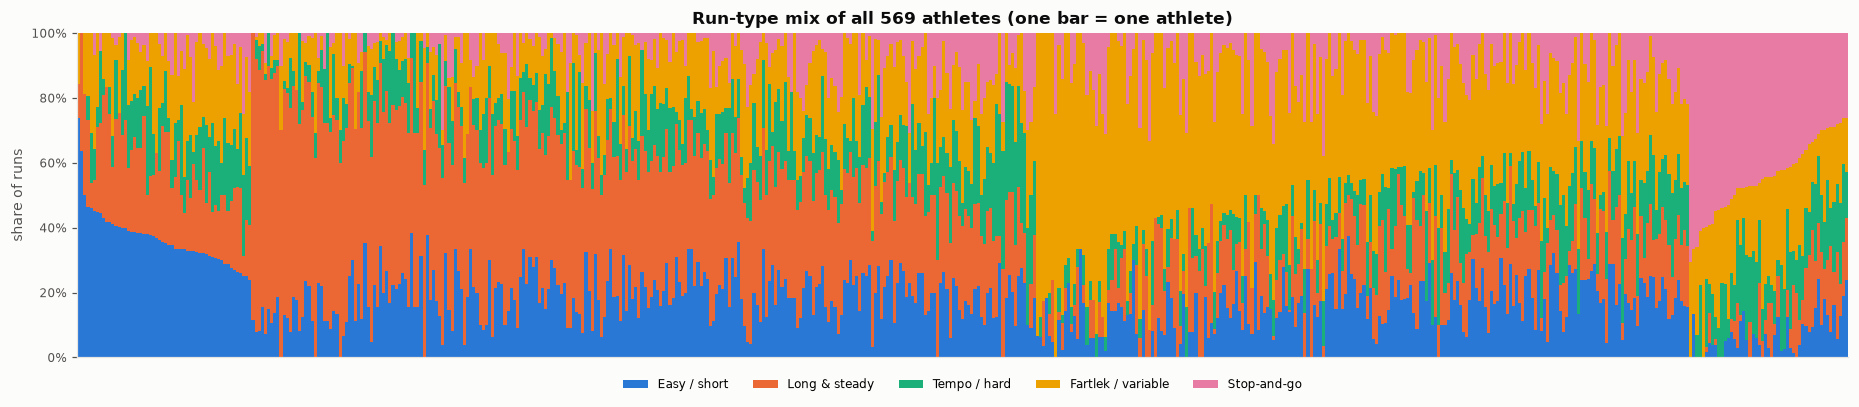

In [14]:
mixes = pd.crosstab(runs.user_id, runs.run_type, normalize="index").reindex(columns=RUN_ORDER, fill_value=0)
dom = mixes.idxmax(axis=1)
order_ = mixes.assign(dom=pd.Categorical(dom, categories=RUN_ORDER),
                      top=mixes.max(axis=1)).sort_values(["dom", "top"], ascending=[True, False]).index

fig, ax = plt.subplots(figsize=(17, 3.8))
bottom = np.zeros(len(order_))
xs = np.arange(len(order_))
for n in RUN_ORDER:
    v = mixes.loc[order_, n].to_numpy()
    ax.bar(xs, v, bottom=bottom, color=RUN_COLOR[n], width=1.0, lw=0, label=n)
    bottom += v
ax.set(xlim=(-0.5, len(xs) - 0.5), ylim=(0, 1), xticks=[], ylabel="share of runs",
       title=f"Run-type mix of all {len(xs)} athletes (one bar = one athlete)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.03), ncol=5)
fig.tight_layout()

### Clustering athletes on their mix

We now cluster athletes on those 5 shares (k-means, k = 3, the same number as notebook 1, so we can compare). Each profile is named after the run type it has *relatively* the most of compared with the average athlete.

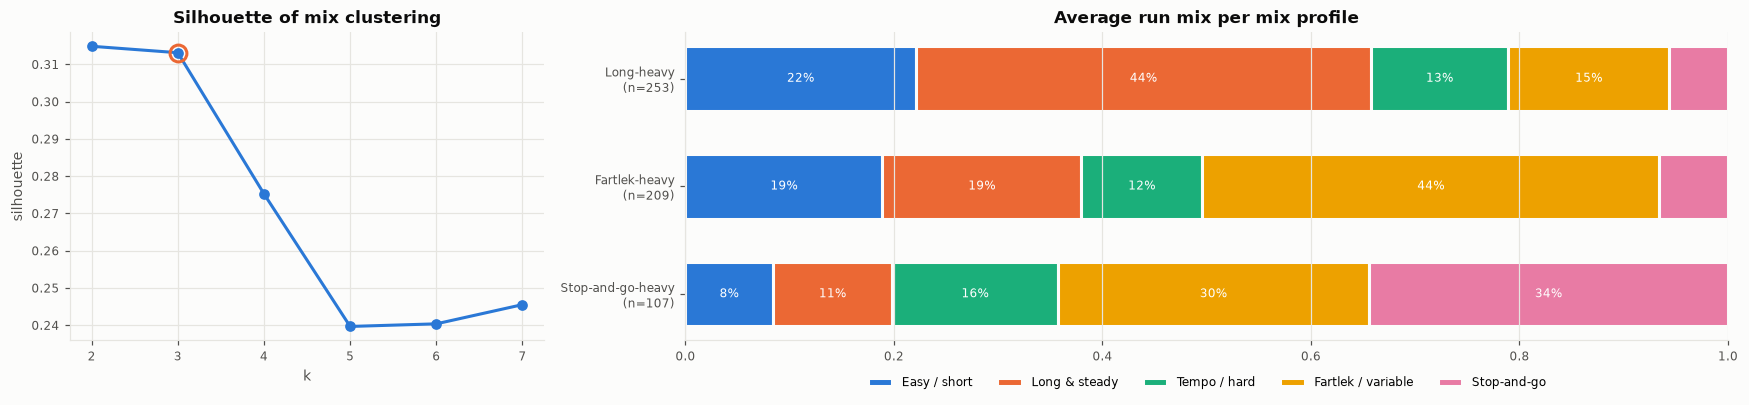

In [15]:
def fit_mix_model(m, k=3, seed=SEED):
    km_ = KMeans(k, n_init=50, random_state=seed).fit(m.values)
    cen = pd.DataFrame(km_.cluster_centers_, columns=RUN_ORDER)
    lift_ = cen / m.mean()
    names_ = {c: f"{lift_.loc[c].idxmax().split(' ')[0]}-heavy" for c in cen.index}
    if len(set(names_.values())) < k:        # two clusters with the same top type: add the 2nd type
        names_ = {c: f"{lift_.loc[c].idxmax().split(' ')[0]}/{lift_.loc[c].nlargest(2).index[1].split(' ')[0]}"
                  for c in cen.index}
    return km_, names_, cen

sil = {k: silhouette_score(mixes.values, KMeans(k, n_init=20, random_state=SEED).fit_predict(mixes.values))
       for k in range(2, 8)}
mix_km, MIX_NAMES, mix_cen = fit_mix_model(mixes)
mixes["mix_profile"] = [MIX_NAMES[l] for l in mix_km.labels_]
MIX_ORDER = [MIX_NAMES[c] for c in mix_cen.sort_values("Easy / short", ascending=False).index]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={"width_ratios": [1, 2.2]})
a1.plot(list(sil), list(sil.values()), color=BLUE, marker="o", ms=6)
a1.plot(3, sil[3], "o", ms=11, mfc="none", mec=ORANGE, mew=2)
a1.set(xlabel="k", ylabel="silhouette", title="Silhouette of mix clustering")

cen_named = mix_cen.rename(index=MIX_NAMES).loc[MIX_ORDER]
left = np.zeros(len(cen_named))
for n in RUN_ORDER:
    v = cen_named[n].to_numpy()
    a2.barh(range(len(v)), v, left=left, color=RUN_COLOR[n], edgecolor="#fcfcfb", lw=2, height=0.6, label=n)
    for yi, (l_, v_) in enumerate(zip(left, v)):
        if v_ > 0.07:
            a2.text(l_ + v_ / 2, yi, f"{v_:.0%}", ha="center", va="center", fontsize=8, color="white")
    left += v
n_mix = mixes.mix_profile.value_counts()
a2.set_yticks(range(len(cen_named)), [f"{n}\n(n={n_mix[n]})" for n in cen_named.index])
a2.invert_yaxis()
a2.set(xlim=(0, 1), title="Average run mix per mix profile")
a2.grid(axis="y", visible=False)
a2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=5)
fig.tight_layout()

### Comparison with notebook 1

Do the mix profiles overlap with the profiles from notebook 1 (clustered on athlete features)? These are different routes to "running profiles", so full agreement isn't expected, but a logical overlap is.

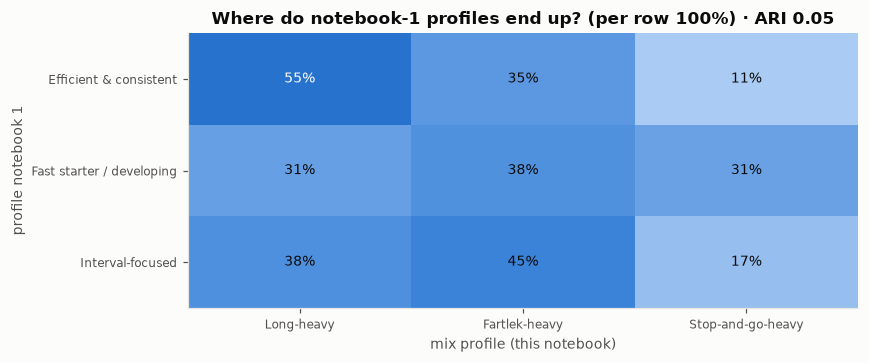

In [16]:
if NB1_LABELS.exists():
    nb1 = pd.read_csv(NB1_LABELS, index_col=0)
    nb1 = nb1[nb1.confidence.notna() & (nb1.label != "not labelled (< 10 runs)")]
    both = mixes.join(nb1[["label"]], how="inner")
    ct1 = pd.crosstab(both.label, both.mix_profile, normalize="index").reindex(columns=MIX_ORDER)
    ari1 = adjusted_rand_score(both.label, both.mix_profile)
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.imshow(ct1.values, cmap=SEQUENTIAL, vmin=0, vmax=1, aspect="auto")
    for r in range(ct1.shape[0]):
        for c in range(ct1.shape[1]):
            v = ct1.iat[r, c]
            ax.text(c, r, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if v > 0.5 else INK)
    ax.set_xticks(range(ct1.shape[1]), ct1.columns)
    ax.set_yticks(range(ct1.shape[0]), ct1.index)
    ax.set(xlabel="mix profile (this notebook)", ylabel="profile notebook 1")
    ax.grid(False)
    ax.set_title(f"Where do notebook-1 profiles end up? (per row 100%) · ARI {ari1:.2f}")
    fig.tight_layout()
else:
    print("Run notebook 1 first (analysis/athlete_profiles) for this comparison.")

**Hardly any overlap (ARI ≈ 0.05), and that is informative.** The two approaches measure different things:

* **Notebook 1** describes **how** someone runs: efficiency, cardiac drift, pacing. *Efficient & consistent* runners end up somewhat more often in *Long-heavy*, but beyond that the profiles are spread across all mixes.
* **Notebook 2** describes **what** someone runs: the mix of easy, long, tempo, variable and stop-and-go runs.

They are complementary rather than competing. A runner can be *efficient* and *fartlek-heavy* at the same time.

## Step 10 · Stability over time: mix profiles vs notebook 1

The same test as notebook 1, step 11, but now **strict for the whole chain**:

1. Athletes with ≥ 20 runs. Each athlete's runs are split chronologically into early / late.
2. The athlete baseline (for `rel_hr` etc.) comes from **early** only.
3. The run-type model is fit on **early runs** only, and labels early and late runs.
4. Run mix per half → the mix model is fit on **early mixes** only → profile early vs late.

Plus the same reference points: random split (noise only) and chance (shuffled).

441 athletes


,agree,ari
chronological,0.701,0.299
random,0.739,0.368


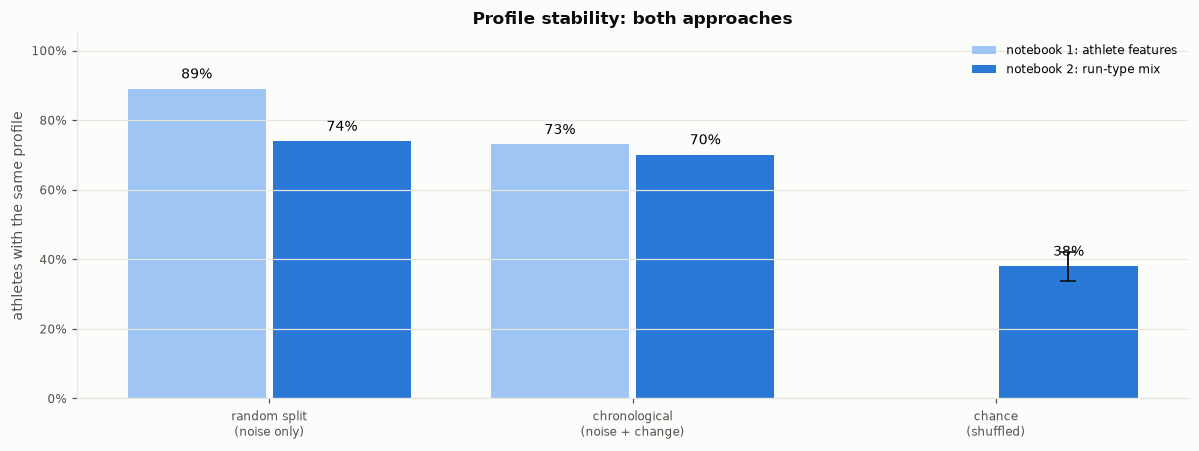

In [17]:
rs = runs.sort_values(["user_id", "date"]).copy()
rs["rank"] = rs.groupby("user_id").cumcount()
rs["n"] = rs.groupby("user_id")["user_id"].transform("size")
rs = rs[rs.n >= 20]
rs["half"] = np.where(rs["rank"] < rs.n // 2, "early", "late")
rs["alt"] = np.where(rs["rank"] % 2 == 0, "A", "B")

def mix_stability(col, first, second, seed=SEED):
    a_runs, b_runs = rs[rs[col] == first].copy(), rs[rs[col] == second].copy()
    bl = make_baseline(a_runs)                                    # baseline from the first part only
    for part in (a_runs, b_runs):
        part[["rel_hr", "rel_speed", "rel_dist"]] = relative_features(part, bl).to_numpy()
    model = fit_run_model(a_runs, seed=seed)
    mix_a = pd.crosstab(a_runs.user_id, model["predict"](a_runs), normalize="index").reindex(columns=RUN_ORDER, fill_value=0)
    mix_b = pd.crosstab(b_runs.user_id, model["predict"](b_runs), normalize="index").reindex(columns=RUN_ORDER, fill_value=0)
    mix_b = mix_b.reindex(mix_a.index, fill_value=0)
    km_, _, _ = fit_mix_model(mix_a, seed=seed)
    pa, pb = km_.predict(mix_a.values), km_.predict(mix_b.values)
    rng_ = np.random.default_rng(seed)
    perm = np.array([(pa == rng_.permutation(pb)).mean() for _ in range(1000)])
    return dict(agree=(pa == pb).mean(), ari=adjusted_rand_score(pa, pb), perm=perm, n=len(pa))

st_chrono = mix_stability("half", "early", "late")
st_random = mix_stability("alt", "A", "B")
print(f"{st_chrono['n']} athletes")

NB1_CHRONO, NB1_RANDOM = 0.73, 0.89          # results from notebook 1, step 11
fig, ax = plt.subplots(figsize=(11, 4.2))
groups_ = ["random split\n(noise only)", "chronological\n(noise + change)", "chance\n(shuffled)"]
x = np.arange(3)
mix_vals = [st_random["agree"], st_chrono["agree"], st_chrono["perm"].mean()]
nb1_vals = [NB1_RANDOM, NB1_CHRONO, np.nan]
b1 = ax.bar(x - 0.2, nb1_vals, width=0.38, color="#9ec5f4", label="notebook 1: athlete features")
b2 = ax.bar(x + 0.2, mix_vals, width=0.38, color=BLUE, label="notebook 2: run-type mix")
ax.errorbar(2 + 0.2, mix_vals[2], yerr=[[mix_vals[2] - np.percentile(st_chrono["perm"], 2.5)],
                                        [np.percentile(st_chrono["perm"], 97.5) - mix_vals[2]]],
            color=INK, capsize=5, lw=1.2)
for bars in (b1, b2):
    for rect in bars:
        h = rect.get_height()
        if not np.isnan(h):
            ax.text(rect.get_x() + rect.get_width() / 2, h + 0.03, f"{h:.0%}", ha="center", fontsize=9)
ax.set_xticks(x, groups_)
ax.set(ylim=(0, 1.05), ylabel="athletes with the same profile", title="Profile stability: both approaches")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
fig.tight_layout()
pd.DataFrame({"chronological": {k: st_chrono[k] for k in ["agree", "ari"]},
              "random": {k: st_random[k] for k in ["agree", "ari"]}}).T.round(3)

## Takeaways

* **Auto-labelling runs works.** Five run types (*easy / short*, *long & steady*, *tempo / hard*, *fartlek / variable*, *stop-and-go*) are recognisable in the time series (step 5), line up logically with the dataset's HR label (step 6), and generalise to new athletes: **~92% the same label** with a model fit on other runners (step 7).
* **Athletes as a mix → profiles.** Clustering on the run mix gives three profiles (*Long-heavy*, *Fartlek-heavy*, *Stop-and-go-heavy*). Over ~11 months, **70%** keep their profile (chance ≈ 38%), almost as stable as notebook 1 (73%), with the whole chain fit strictly on early data only.
* **More noise per athlete.** Within the same period, mix profiles agree less (74%) than notebook 1's (89%). A mix of ~10 runs is coarse (each run = 10%). Mix profiles therefore need more runs before they're reliable.
* **Different, not better or worse.** The mix profiles barely overlap with notebook 1 (ARI ≈ 0.05): notebook 1 = *how* you run, notebook 2 = *what* you run. A combination is the most informative, e.g. *"efficient runner, mostly long runs"*.
* **Lesson from the feature choice:** `split_ratio` created a seemingly neat split (slow at start vs slow at end) that turned out not to be stable across athletes. Always check whether clusters reproduce on *other* data, not just whether they look nice.

**For practice:** label every new run immediately with `label_run` (only needs the athlete's baseline, i.e. after a few runs), and show the athlete profile from ~10 runs (notebook 1) together with their run mix.

## Save results

In [18]:
runs[["workout_id", "user_id", "date", "workout_type", "run_type", *FEATURES]].to_csv(OUT / "run_labels.csv", index=False)
mixes.round(4).to_csv(OUT / "athlete_run_mix.csv")
print(f"Saved to {OUT.relative_to(ROOT)}")

Saved to analysis\run_types\output
